In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "1" # whatever is free
# os.environ["JAX_PLATFORM_NAME"] = "cpu"
# os.environ["JAX_LOG_COMPILES"] = "1" # to see jit compiliation triggers

from loguru import logger
import jax
logger.info(f'JAX is using: {jax.devices()}')

2026-06-05 21:03:50.352 | INFO     | __main__:<module>:8 - JAX is using: [CudaDevice(id=0)]


In [ ]:
"""Extract pre-head embeddings from a Kinetix ActorCriticTransformer checkpoint.

This module loads a trained checkpoint, strips the actor/critic head parameters,
and exposes a pure JAX function that maps ``EntityObservation`` → L2-normalized
embedding vectors suitable for environment similarity matching (analogous to how
``DinoMatchingRepo`` uses DINO embeddings).

Usage::

    from apa.utils.embedding import make_embedding_fn

    encode = make_embedding_fn(config, "path/to/full_model.pbz2")
    obs = env.get_obs(env_state.env_state)         # EntityObservation
    embeddings = encode(obs)                        # (B, D), L2-normalized
"""

from __future__ import annotations

from typing import Any, Callable

import flax.linen as nn
import jax
import jax.numpy as jnp
import numpy as np
from flax.linen.initializers import constant, orthogonal

from kinetix.models.transformer_model import Transformer


# ── Helpers ─────────────────────────────────────────────────────────────────

def _mask_out_inactives(flat_active_mask, matrix_attention_mask):
    """Replicate of the local function inside ActorCriticTransformer.__call__."""
    return matrix_attention_mask & (flat_active_mask[:, None]) & (flat_active_mask[None, :])


# ── Param filtering ─────────────────────────────────────────────────────────

def _is_head_param(path: tuple[str, ...]) -> bool:
    """Return True if *path* belongs to the actor/critic head (GeneralActorCriticRNN).

    Flax params are stored as ``{'params': {'Dense_0': ..., 'GeneralActorCriticRNN_0': ...}}``,
    so flattened keys look like ``('GeneralActorCriticRNN_0', 'Dense_0', 'bias')``.
    """
    return (
        len(path) >= 2
        and path[0] == "GeneralActorCriticRNN_0"
        and (path[1].startswith("Dense_") or path[1] == "log_std")
    )


def _filter_backbone_params(full_params: dict) -> dict:
    """Strip ``GeneralActorCriticRNN_0`` entries from a Flatten-able param dict."""
    from flax.traverse_util import flatten_dict, unflatten_dict

    flat = flatten_dict(full_params)
    backbone_flat = {k: v for k, v in flat.items() if not _is_head_param(k)}
    return unflatten_dict(backbone_flat)


# ── Extractor module ────────────────────────────────────────────────────────

class TransformerEmbeddingExtractor(nn.Module):
    """Replicates the ``ActorCriticTransformer`` backbone exactly.

    The submodule structure (encoder ``Dense`` layers, ``Transformer`` block)
    is identical to ``ActorCriticTransformer`` so that checkpoint parameter
    names align automatically after stripping the head entries.

    Stops *before* ``GeneralActorCriticRNN`` — returns the pooled embedding.
    """

    transformer_size: int
    transformer_encoder_size: int
    transformer_depth: int
    num_heads: int
    activation: str
    aggregate_mode: str          # "dummy" | "mean" | "dummy_and_mean"
    full_attention_mask: bool

    @nn.compact
    def __call__(self, hidden, x):
        del hidden  # not used by the backbone; kept for API compatibility

        activation = nn.relu if self.activation == "relu" else nn.tanh

        og_obs, dones = x
        obs = og_obs  # EntityObservation  (T, B, N, L)

        # ── Entity encoders (identical to ActorCriticTransformer) ──────────
        def _single_encoder(features, entity_id, concat=True):
            num_to_remove = 1 if concat else 0
            emb = activation(
                nn.Dense(
                    self.transformer_encoder_size - num_to_remove,
                    kernel_init=orthogonal(np.sqrt(2)),
                    bias_init=constant(0.0),
                )(features)
            )
            if concat:
                id_1h = jnp.zeros((*emb.shape[:3], 1)).at[:, :, :, 0].set(entity_id)
                return jnp.concatenate([emb, id_1h], axis=-1)
            return emb

        circle_encodings = _single_encoder(obs.circles, 0)
        polygon_encodings = _single_encoder(obs.polygons, 1)
        joint_encodings = _single_encoder(obs.joints, -1, False)
        thruster_encodings = _single_encoder(obs.thrusters, -1, False)

        shape_encodings = jnp.concatenate([polygon_encodings, circle_encodings], axis=2)
        shape_mask = jnp.concatenate([obs.polygon_mask, obs.circle_mask], axis=2)

        joint_indexes = obs.joint_indexes
        thruster_indexes = obs.thruster_indexes

        # ── Optional dummy token ───────────────────────────────────────────
        if self.aggregate_mode in ("dummy", "dummy_and_mean"):
            T, B, _, K = circle_encodings.shape
            dummy = jnp.ones((T, B, 1, K))
            shape_encodings = jnp.concatenate([dummy, shape_encodings], axis=2)
            shape_mask = jnp.concatenate(
                [jnp.ones((T, B, 1), dtype=bool), shape_mask], axis=2
            )
            N = obs.attention_mask.shape[-1]
            overall_mask = (
                jnp.ones((T, B, obs.attention_mask.shape[2], N + 1, N + 1), dtype=bool)
                .at[:, :, :, 1:, 1:]
                .set(obs.attention_mask)
            )
            overall_mask = jax.vmap(jax.vmap(_mask_out_inactives))(shape_mask, overall_mask)
            joint_indexes = joint_indexes + 1
            thruster_indexes = thruster_indexes + 1
        else:
            overall_mask = obs.attention_mask

        if self.full_attention_mask:
            overall_mask = jnp.ones(overall_mask.shape, dtype=bool)
            overall_mask = jax.vmap(jax.vmap(_mask_out_inactives))(shape_mask, overall_mask)

        # ── Transformer ────────────────────────────────────────────────────
        embedding = Transformer(
            num_layers=self.transformer_depth,
            num_heads=self.num_heads,
            qkv_features=self.transformer_size,
            encoder_size=self.transformer_encoder_size,
            gating=True,
            gating_bias=0.0,
        )(
            shape_encodings,
            jnp.repeat(overall_mask, repeats=self.num_heads // overall_mask.shape[2], axis=2),
            joint_encodings,
            obs.joint_mask,
            joint_indexes,
            thruster_encodings,
            obs.thruster_mask,
            thruster_indexes,
        )

        # ── Pool ───────────────────────────────────────────────────────────
        if self.aggregate_mode in ("mean", "dummy_and_mean"):
            embedding = jnp.mean(embedding, axis=2, where=shape_mask[..., None])
        else:
            embedding = embedding[:, :, 0]

        return embedding  # (T, B, transformer_encoder_size)


# ── Public API ──────────────────────────────────────────────────────────────

def make_embedding_fn(
    config: dict[str, Any],
    checkpoint_path: str,
) -> Callable[[Any], jnp.ndarray]:
    """Build a jit-compatible function that encodes entity observations → embeddings.

    Args:
        config: Flat configuration dict (from ``load_config``).  Must contain
            ``transformer_size``, ``transformer_encoder_size``,
            ``transformer_depth``, ``num_heads``, ``activation``,
            ``aggregate_mode``, ``full_attention_mask``.
        checkpoint_path: Path to a ``full_model.pbz2`` checkpoint saved by
            ``backbone.py`` or ``ppo.py``.

    Returns:
        A callable ``encode(obs) -> embeddings`` where:
          - ``obs`` is an ``EntityObservation`` pytree with leading batch dim
            ``(B, ...)`` (no time axis).
          - ``embeddings`` is a ``(B, D)`` float32 array, **L2-normalized**
            (each row is a unit vector).

        The returned function is pure and can be wrapped with ``jax.jit``.
    """
    from kinetix.util.saving import load_params

    # 1. Load and filter checkpoint
    payload = load_params(checkpoint_path)
    raw_params = payload["params"]  # may be {'params': {...}} or just {...}

    # Unwrap the Flax 'params' wrapper if present, filter, then re-wrap.
    if isinstance(raw_params, dict) and "params" in raw_params:
        inner = raw_params["params"]
        backbone_params = {"params": _filter_backbone_params(inner)}
    else:
        backbone_params = _filter_backbone_params(raw_params)

    # 2. Instantiate the extractor module
    extractor = TransformerEmbeddingExtractor(
        transformer_size=int(config["transformer_size"]),
        transformer_encoder_size=int(config["transformer_encoder_size"]),
        transformer_depth=int(config["transformer_depth"]),
        num_heads=int(config["num_heads"]),
        activation=config["activation"],
        aggregate_mode=config.get("aggregate_mode", "dummy_and_mean"),
        full_attention_mask=bool(config.get("full_attention_mask", False)),
    )

    # 3. Define the encoding function
    def encode(obs):
        """obs: EntityObservation with leading (B,) batch dim → (B, D) L2-normed."""
        # Add time dim: (B, ...) → (1, B, ...)
        obs_t = jax.tree.map(lambda x: jnp.expand_dims(x, 0), obs)
        B = obs.circles.shape[0]
        dones = jnp.zeros((1, B), dtype=bool)
        # hidden is a dummy — the backbone ignores it
        from kinetix.models import ScannedRNN
        hidden = ScannedRNN.initialize_carry(B)

        emb = extractor.apply(backbone_params, hidden, (obs_t, dones))
        emb = jnp.squeeze(emb, axis=0)  # (B, D)
        # L2-normalize (like DINO)
        emb = emb / (jnp.linalg.norm(emb, axis=-1, keepdims=True) + 1e-12)
        return emb

    return encode


def load_and_validate(checkpoint_path: str, config: dict[str, Any]) -> dict:
    """Load checkpoint and print diagnostic info.

    Useful in notebooks before building the full encoding pipeline.
    Returns the raw (unfiltered) params dict.
    """
    from kinetix.util.saving import load_params
    from flax.traverse_util import flatten_dict

    payload = load_params(checkpoint_path)
    raw_params = payload["params"]  # {'params': {...}} or just the inner dict

    # Flax wraps params in a top-level 'params' key — flatten the inner dict
    # so that keys look like ('GeneralActorCriticRNN_0', 'Dense_0', 'bias').
    if isinstance(raw_params, dict) and "params" in raw_params:
        inner_params = raw_params["params"]
        nested = True
    else:
        inner_params = raw_params
        nested = False

    flat = flatten_dict(inner_params)
    head_keys = [k for k in flat if _is_head_param(k)]
    backbone_keys = [k for k in flat if not _is_head_param(k)]

    print(f"Checkpoint: {checkpoint_path}")
    print(f"  Step: {payload.get('step', 'N/A')}")
    print(f"  Params nesting: {'wrapped (params/params/...)' if nested else 'flat'}")
    print(f"  Total param leaves: {len(flat)}")
    print(f"  Backbone leaves:    {len(backbone_keys)}")
    print(f"  Head leaves:        {len(head_keys)}")
    print(f"  Embedding dim:      {int(config['transformer_encoder_size'])}")

    # Show a few backbone key paths for sanity
    print("\n  Sample backbone keys:")
    for k in sorted(backbone_keys)[:8]:
        print(f"    {'/'.join(str(x) for x in k)}")

    if head_keys:
        print("\n  Sample head keys (stripped):")
        for k in sorted(head_keys)[:4]:
            print(f"    {'/'.join(str(x) for x in k)}")

    return raw_params

In [3]:
from pathlib import Path
from apa.utils.config import load_config

config_dir = Path('../configs').resolve()
project_root = config_dir.parent  # /mediaPFM/data/sobhan/SP2026_OpenEndedLearning

config = load_config(
    config_path=str(config_dir),
    config_name='config',
    overrides=[
        f'hydra.searchpath=[file://{project_root}/third_party/kinetix/configs]'
    ],
)

In [4]:
CHECKPOINT_PATH = "../checkpoints/ppo_training/Kinetix-SymbolicEntity-MultiDiscrete-PPO-0M-2048-115095500-0B/full_model.pbz2"

params = load_and_validate(CHECKPOINT_PATH, config)

Checkpoint: ../checkpoints/ppo_training/Kinetix-SymbolicEntity-MultiDiscrete-PPO-0M-2048-115095500-0B/full_model.pbz2
  Step: 0
  Params nesting: wrapped (params/params/...)
  Total param leaves: 96
  Backbone leaves:    72
  Head leaves:        24
  Embedding dim:      128

  Sample backbone keys:
    Dense_0/bias
    Dense_0/kernel
    Dense_1/bias
    Dense_1/kernel
    Dense_2/bias
    Dense_2/kernel
    Dense_3/bias
    Dense_3/kernel

  Sample head keys (stripped):
    GeneralActorCriticRNN_0/Dense_0/bias
    GeneralActorCriticRNN_0/Dense_0/kernel
    GeneralActorCriticRNN_0/Dense_1/bias
    GeneralActorCriticRNN_0/Dense_1/kernel


In [12]:
# ── Build the jitted encoder ─────────────────────────────────────────────

encode = make_embedding_fn(config, CHECKPOINT_PATH)
encode = jax.jit(encode)  # compile once, fast thereafter

print(f"Encoder built successfully.")

Encoder built successfully.


In [6]:
from apa.utils.env import make_env_from_config, get_random_envs
import jax.random as jr

rng = jr.PRNGKey(0)

env, env_params, static_env_params = make_env_from_config(config)

# ── Get some random envs and their observations ──────────────────────────
rng, sub_rng = jr.split(rng)
test_env_states = get_random_envs(5, env, env_params, sub_rng)

# Get entity observations (symbolic_entity)
obs = jax.vmap(env.get_obs)(test_env_states.env_state)

print(f"Observation type: {type(obs)}")
print(f"  circles shape:  {obs.circles.shape}")
print(f"  polygons shape: {obs.polygons.shape}")

Observation type: <class 'kinetix.render.renderer_symbolic_entity.EntityObservation'>
  circles shape:  (5, 4, 19)
  polygons shape: (5, 12, 27)


In [13]:
# ── Encode ───────────────────────────────────────────────────────────────
embeddings = encode(obs)

print(f"Embeddings shape: {embeddings.shape}")  # expect (5, 128)
print(f"dtype: {embeddings.dtype}")

# Verify L2 norm
norms = jnp.linalg.norm(embeddings, axis=1)
print(f"L2 norms: {norms}")  # all should be ~1.0

# Quick similarity check
sim = embeddings @ embeddings.T  # (5, 5) cosine similarity matrix
print(f"Pairwise cosine similarities:\n{np.array(sim)}")

Embeddings shape: (5, 128)
dtype: float32
L2 norms: [2.9075527 3.0455437 4.1215134 2.9973    2.9950879]
Pairwise cosine similarities:
[[ 8.454167   7.838783   9.167067   8.072201   7.128584 ]
 [ 7.838783   9.275764   9.726899   7.7208543  6.9920382]
 [ 9.167067   9.726899  16.987667   9.523798   7.1549935]
 [ 8.072201   7.7208543  9.523798   8.98406    7.4583397]
 [ 7.128584   6.9920382  7.1549935  7.4583397  8.970303 ]]


2026-06-05 21:09:48.931132: W external/xla/xla/service/gpu/autotuning/dot_search_space.cc:200] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs?Working around this by using the full hints set instead.
2026-06-05 21:09:48.931182: W external/xla/xla/service/gpu/autotuning/dot_search_space.cc:200] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs?Working around this by using the full hints set instead.
2026-06-05 21:09:48.931193: W external/xla/xla/service/gpu/autotuning/dot_search_space.cc:200] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs?Working around this by using the full hints set instead.
2026-06-05 21:09:48.931202: W external/xla/xla/service/gpu/au

Same env self-similarity: 1.000000  (should be ~1.0)
Env 0 vs Env 1 similarity:  0.885201


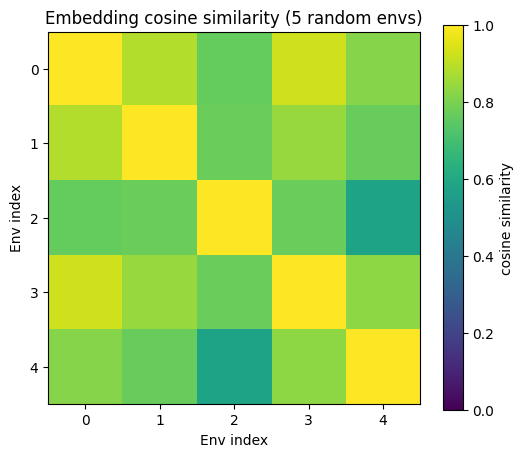

In [9]:
# ── Sanity check: same env → similar, different envs → less similar ──────
# Encode the same env twice
single_env_state = jax.tree.map(lambda x: x[0], test_env_states.env_state)
obs0 = env.get_obs(single_env_state)
emb0_a = encode(jax.tree.map(lambda x: x[None, ...], obs0))
emb0_b = encode(jax.tree.map(lambda x: x[None, ...], obs0))

same_sim = float((emb0_a @ emb0_b.T)[0, 0])
print(f"Same env self-similarity: {same_sim:.6f}  (should be ~1.0)")

# Compare env 0 vs env 1
cross_sim = float(embeddings[0] @ embeddings[1])
print(f"Env 0 vs Env 1 similarity:  {cross_sim:.6f}")

# Show full similarity matrix
import matplotlib.pyplot as plt
plt.figure(figsize=(6, 5))
plt.imshow(np.array(sim), cmap='viridis', vmin=0, vmax=1)
plt.colorbar(label='cosine similarity')
plt.title('Embedding cosine similarity (5 random envs)')
plt.xlabel('Env index')
plt.ylabel('Env index')
plt.show()

In [10]:
# Check if embedding magnitude carries signal
mags = jnp.linalg.norm(embeddings, axis=1, keepdims=False)
unnormalized_emb = embeddings * mags[:, None]  # undo the normalization
print(f"Embedding magnitudes: {np.array(mags)}")
# If magnitudes vary wildly (e.g., 0.1 to 100), normalization is probably good
# If they're all ~similar, normalization is harmless

Embedding magnitudes: [0.99999994 1.0000001  0.99999994 1.         1.        ]
